# Sonnensystem – Teil 1: Jupiter und die (fixierte) Sonne

Die Sonne sitzt fest im Ursprung, Jupiter bewegt sich in ihrem Gravitationsfeld:
$$
\dot q = v, \qquad \dot v = a(q) = -GM\,\frac{q}{\|q\|^3}.
$$
Erhaltungsgrößen (pro Masse von Jupiter):
$$
E = \frac12\|v\|^2 - \frac{GM}{\|q\|}, \qquad L = q\times v .
$$
Einheiten: AU, Sonnenmassen, Tage.

In [1]:
using LinearAlgebra
using Plots
using LaTeXStrings

const G = 2.95912208286e-4     # Gravitationskonstante in AU^3 / (M_sun * Tag^2)
const m_sun = 1.00000597682    # Masse der Sonne in M_sun (inklusive der inneren Planeten)
const GM = G * m_sun

q_jup = [-3.5023653, -3.8169847, -1.5507963]       # Position von Jupiter
v_jup = [0.00565429, -0.00412490, -0.00190589]     # Geschwindigkeit von Jupiter

3-element Vector{Float64}:
  0.00565429
 -0.0041249
 -0.00190589

## Aufgabe 1: Beschleunigung und Erhaltungsgrößen

In [2]:
raw"""
computes the acceleration a(q) = -GM q / |q|^3 of a body at position q (3-vector)
in the field of a fixed sun at the origin
"""
function acceleration_fixed_sun(q, GM)
    return -GM * q / norm(q)^3
end

"energy per mass: E = |v|^2 / 2 - GM / |q|"
energy_fixed_sun(q, v, GM) = dot(v, v) / 2 - GM / norm(q)

"angular momentum per mass: L = q x v"
angular_momentum(q, v) = cross(q, v)

# Kurzer Test: Beschleunigung zeigt zur Sonne, E < 0 (gebundene Bahn)
println("a(q_0) = ", acceleration_fixed_sun(q_jup, GM))
println("E_0    = ", energy_fixed_sun(q_jup, v_jup, GM))
println("L_0    = ", angular_momentum(q_jup, v_jup))

a(q_0) = [6.554517485105713e-6, 7.143313393531791e-6, 2.902244795592066e-6]
E_0    = -2.8413916966091867e-5
L_0    = [0.0008778733120129991, -0.015443775012744, 0.036029245045333]


## Aufgabe 2: Explizites Eulerverfahren und Zeitintegration

`integrate` verwendet nur `+`, `*` und `copy` auf den Zuständen. Deshalb funktioniert es für 3-Vektoren genauso wie später für $3\times N$-Matrizen.

In [3]:
raw"""
computes (q_{n+1}, v_{n+1}) from (q_n, v_n) using the explicit Euler method
acc: function that computes the acceleration, a = acc(q)
h: time-step size
"""
function euler_step(acc, q, v, h)
    q_new = q + h * v
    v_new = v + h * acc(q)
    return q_new, v_new
end

raw"""
time-evolves the state (q_0, v_0).
step: function that evolves the state a single time step: q_new, v_new = step(acc, q, v, h)
acc: function that computes the acceleration, a = acc(q)
h: time-step size
N_steps: number of time steps

returns the times t_n and the computed states q_n and v_n (as vectors of states) including the initial_state
"""
function integrate(step, acc, q_0, v_0, h, N_steps)
    t = [n * h for n in 0:N_steps]
    q_t = [copy(q_0)]
    v_t = [copy(v_0)]
    for n in 1:N_steps
        q_new, v_new = step(acc, q_t[end], v_t[end], h)
        push!(q_t, q_new)
        push!(v_t, v_new)
    end
    return t, q_t, v_t
end

integrate (generic function with 1 method)

## Aufgabe 3: Umlaufperiode und Simulation mit Euler

In [4]:
# Umlaufperiode aus der Energie
E_0 = energy_fixed_sun(q_jup, v_jup, GM)
a_half = -GM / (2 * E_0)               # große Halbachse
T = 2π * sqrt(a_half^3 / GM)
println("große Halbachse a = $(a_half) AU")
println("Umlaufperiode   T = $(T) Tage = $(T / 365.25) Jahre")

h = T / 100
N_steps = 1000
acc = q -> acceleration_fixed_sun(q, GM)

t, q_euler, v_euler = integrate(euler_step, acc, q_jup, v_jup, h, N_steps)

große Halbachse a = 5.207201408611451 AU
Umlaufperiode   T = 4340.139542907673 Tage = 11.88265446381293 Jahre


([0.0, 43.40139542907673, 86.80279085815346, 130.2041862872302, 173.60558171630692, 217.00697714538364, 260.4083725744604, 303.8097680035371, 347.21116343261383, 390.61255886169056  …  43010.78287021504, 43054.184265644115, 43097.58566107319, 43140.98705650227, 43184.38845193134, 43227.78984736042, 43271.1912427895, 43314.59263821857, 43357.99403364765, 43401.39542907673], [[-3.5023653, -3.8169847, -1.5507963], [-3.2569612238393257, -3.9960111160053984, -1.6335145855343232], [-2.999210526807223, -4.1615818074000765, -1.7107659673265054], [-2.729980296011275, -4.313068098835946, -1.7822598394188116], [-2.450177092313618, -4.4498837656909105, -1.8477228303668842], [-2.1607456008436214, -4.5714877986384925, -1.9069000211412042], [-1.8626669341865474, -4.6773872832884145, -1.9595562208159554], [-1.556956552596963, -4.767140354550737, -2.0054772836192187], [-1.2446617698408948, -4.840359179287858, -2.0444714482050257], [-0.9268588188421942, -4.896712914844867, -2.0763706773114023]  …  [1.60

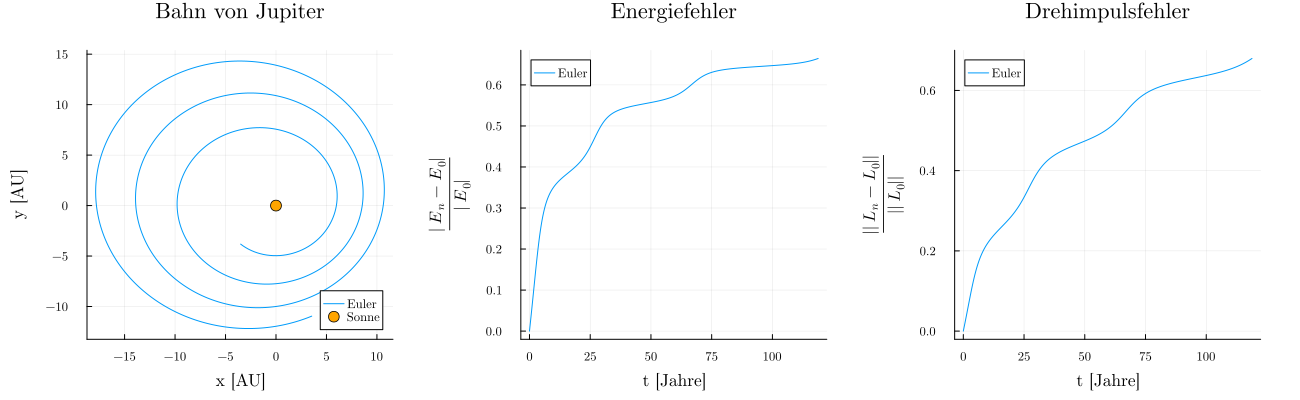

In [5]:
# Hilfsfunktionen für die relativen Fehler (werden auch später wiederverwendet)
L_0 = angular_momentum(q_jup, v_jup)

energy_error(q_t, v_t) = [abs(energy_fixed_sun(q, v, GM) - E_0) / abs(E_0) for (q, v) in zip(q_t, v_t)]
angmom_error(q_t, v_t) = [norm(angular_momentum(q, v) - L_0) / norm(L_0) for (q, v) in zip(q_t, v_t)]

# x- und y-Koordinaten aus dem Vektor von Zuständen
xs(q_t) = [q[1] for q in q_t]
ys(q_t) = [q[2] for q in q_t]

p1 = plot(xs(q_euler), ys(q_euler), label = "Euler", aspect_ratio = :equal,
          xlabel = "x [AU]", ylabel = "y [AU]", title = "Bahn von Jupiter", fontfamily = "Computer Modern")
scatter!(p1, [0], [0], label = "Sonne", color = :orange, markersize = 6)

p2 = plot(t / 365.25, energy_error(q_euler, v_euler), label = "Euler",
          xlabel = "t [Jahre]", ylabel = L"$\frac{|E_n - E_0|}{|E_0|}$", title = "Energiefehler")

p3 = plot(t / 365.25, angmom_error(q_euler, v_euler), label = "Euler",
          xlabel = "t [Jahre]", ylabel = L"$\frac{||L_n - L_0||}{||L_0||}$", title = "Drehimpulsfehler")

plot(p1, p2, p3, layout = (1, 3), size = (1300, 400), margin = 8Plots.mm)

**Kommentar**

* **Umlaufperiode:** $T \approx 4340$ Tage $\approx 11{,}9$ Jahre. Das passt zur bekannten Umlaufzeit von Jupiter.
* **Bahn:** Die Euler-Bahn ist keine geschlossene Ellipse, sondern eine **nach außen laufende Spirale**. Nach 10 Umläufen ist Jupiter rund 18 AU statt etwa 5 AU von der Sonne entfernt.
* **Energie:** Der Energiefehler wächst stetig und erreicht am Ende etwa 66 %. Das explizite Eulerverfahren pumpt in jedem Schritt Energie ins System. $E$ wird größer, also weniger negativ, und dadurch wächst die Bahn.
* **Drehimpuls:** Auch der Drehimpuls ist nicht erhalten, sein Fehler wächst auf etwa 68 %.

Fazit: Mit 100 Schritten pro Umlauf ist das explizite Eulerverfahren für Langzeitsimulationen unbrauchbar. Es ist nur erster Ordnung und erhält keine der beiden Größen.

## Aufgabe 4: Störmer–Verlet

$$
v_{n+1/2} = v_n + \tfrac h2 a(q_n),\qquad
q_{n+1} = q_n + h\,v_{n+1/2},\qquad
v_{n+1} = v_{n+1/2} + \tfrac h2 a(q_{n+1})
$$

In [6]:
raw"""
computes (q_{n+1}, v_{n+1}) from (q_n, v_n) using the Störmer-Verlet (leapfrog) method
"""
function verlet_step(acc, q, v, h)
    v_half = v + (h / 2) * acc(q)
    q_new = q + h * v_half
    v_new = v_half + (h / 2) * acc(q_new)
    return q_new, v_new
end

t, q_verlet, v_verlet = integrate(verlet_step, acc, q_jup, v_jup, h, N_steps)

([0.0, 43.40139542907673, 86.80279085815346, 130.2041862872302, 173.60558171630692, 217.00697714538364, 260.4083725744604, 303.8097680035371, 347.21116343261383, 390.61255886169056  …  43010.78287021504, 43054.184265644115, 43097.58566107319, 43140.98705650227, 43184.38845193134, 43227.78984736042, 43271.1912427895, 43314.59263821857, 43357.99403364765, 43401.39542907673], [[-3.5023653, -3.8169847, -1.5507963], [-3.2507879134036117, -3.9892832537000382, -1.6307811336632527], [-2.987692057636972, -4.1474466385138875, -1.7049876444362064], [-2.713951465274519, -4.290833240392788, -1.773119518324228], [-2.430484275376556, -4.418841819283695, -1.8348966654760615], [-2.1382517002277477, -4.530914129299722, -1.8900563757938726], [-1.8382565111520195, -4.626537610060506, -1.9383545094582717], [-1.5315413205992465, -4.705248141303856, -1.9795667195382454], [-1.2191866372038067, -4.766632849953354, -2.0134897026177687], [-0.9023086703365342, -4.810332955664669, -2.039942472019881]  …  [-5.25265

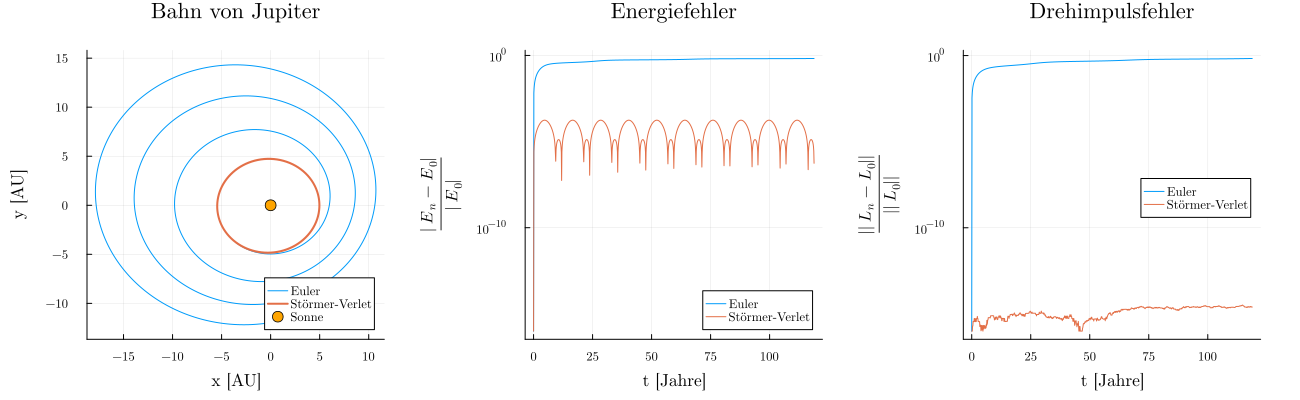

In [7]:
clip(x) = max(x, 1e-16)   # exakte Nullen für die log-Skala vermeiden

p1 = plot(xs(q_euler), ys(q_euler), label = "Euler", aspect_ratio = :equal,
          xlabel = "x [AU]", ylabel = "y [AU]", title = "Bahn von Jupiter", fontfamily = "Computer Modern")
plot!(p1, xs(q_verlet), ys(q_verlet), label = "Störmer-Verlet", linewidth = 2)
scatter!(p1, [0], [0], label = "Sonne", color = :orange, markersize = 6)

p2 = plot(t / 365.25, clip.(energy_error(q_euler, v_euler)), label = "Euler",
          yscale = :log10, xlabel = "t [Jahre]", ylabel = L"$\frac{|E_n - E_0|}{|E_0|}$",
          title = "Energiefehler", legend = :bottomright)
plot!(p2, t / 365.25, clip.(energy_error(q_verlet, v_verlet)), label = "Störmer-Verlet")

p3 = plot(t / 365.25, clip.(angmom_error(q_euler, v_euler)), label = "Euler",
          yscale = :log10, xlabel = "t [Jahre]", ylabel = L"$\frac{||L_n - L_0||}{||L_0||}$",
          title = "Drehimpulsfehler", legend = :right)
plot!(p3, t / 365.25, clip.(angmom_error(q_verlet, v_verlet)), label = "Störmer-Verlet")

plot(p1, p2, p3, layout = (1, 3), size = (1300, 400), margin = 8Plots.mm)

**Vergleich der beiden Verfahren**

* **Bahn:** Störmer–Verlet liefert bei gleichem Aufwand eine stabile, geschlossene Ellipse. Der Abstand zur Sonne bleibt zwischen etwa 5,0 und 5,5 AU, während Euler nach außen spiralt.
* **Energie:** Der Energiefehler von Störmer–Verlet bleibt **beschränkt**, höchstens etwa $2\cdot10^{-4}$. Er wächst nicht, sondern **oszilliert** periodisch mit der Umlaufzeit: Er ist am größten in Sonnennähe und geht nach jedem vollen Umlauf fast wieder auf null zurück. Das ist typisch für **symplektische** Verfahren. Bei Euler wächst der Fehler dagegen systematisch, und das um mehrere Größenordnungen stärker.
* **Drehimpuls:** Störmer–Verlet erhält den Drehimpuls **bis auf Rundungsfehler exakt** (etwa $10^{-15}$). Der Grund: Die Kraft ist zentral ($a \parallel q$), und jeder Teilschritt erhält $q\times v$ exakt. Bei Euler wächst der Fehler auf etwa 68 %.

Fazit: Bei gleichen Kosten (eine Kraftauswertung pro Schritt, weil man $a(q_{n+1})$ im nächsten Schritt wiederverwenden kann) ist Störmer–Verlet für Himmelsmechanik dem expliziten Euler-Verfahren klar überlegen.

# Teil 2 Implicit Midpoint Rule für die Jupiter-Bahn

Wir simulieren Jupiter im Gravitationsfeld der (fixierten) Sonne. Die Bewegungsgleichungen sind

$$
\dot q = v, \qquad \dot v = a(q) = -GM \,\frac{q}{\|q\|^3}.
$$

Ein Zeitschritt der Länge $h$ führt von $(q_n, v_n)$ nach $(q_{n+1}, v_{n+1})$. Die **implicit midpoint rule** wertet die Beschleunigung in der *Mitte* des Schritts aus:

$$
v_{n+1} = v_n + h\, a(\bar q), \qquad
q_{n+1} = q_n + h\,\frac{v_n + v_{n+1}}{2}, \qquad
\bar q = \frac{q_n + q_{n+1}}{2}.
$$

Das Verfahren ist *implizit*: Die Unbekannte $q_{n+1}$ steckt auch in $\bar q$ auf der rechten Seite.

## Voraussetzungen

Beschleunigung im Feld der fixierten Sonne und ihre Jacobi-Matrix $\partial a/\partial q$ (3×3). Die Jacobi-Matrix brauchen wir später im Newton-Verfahren.

In [8]:
# Jacobi-Matrix (3x3) der Beschleunigung a(q) = -GM q/|q|^3  (gegeben)
function jacobian_fixed_sun(q, GM)
    r = norm(q)
    return -GM * (I / r^3 - 3 * q * q' / r^5)
end

jacobian_fixed_sun (generic function with 1 method)

## Herleitung

Setzt man die erste Gleichung in die zweite ein, bleibt **eine** Gleichung für **eine** Unbekannte $q_{n+1}$:

$$
0 = F(q_{n+1}) = q_{n+1} - q_n - h\, v_n - \frac{h^2}{2}\, a\!\left(\frac{q_n + q_{n+1}}{2}\right).
$$

Das ist nichtlinear, weil $a(q) = -GM\, q/\|q\|^3$ nichtlinear ist. Wir lösen es mit dem **Newton-Verfahren**. Da $F:\mathbb{R}^3\to\mathbb{R}^3$ ist, wird aus der Ableitung die Jacobi-Matrix

$$
J_F = I - \frac{h^2}{4}\,\frac{\partial a}{\partial q}(\bar q).
$$

(Der Faktor $\tfrac12$ aus $\partial \bar q/\partial q_{n+1}$ kommt über die Kettenregel dazu.) Ein Newton-Schritt löst ein lineares Gleichungssystem:

$$
J_F\,\delta = F(q_{n+1}), \qquad q_{n+1} \leftarrow q_{n+1} - \delta.
$$

**Ablauf eines Zeitschritts**

1. Startwert: expliziter Euler-Schritt $q_{n+1}^{(0)} = q_n + h\,v_n$.
2. Newton wiederholen, bis $\|\delta\|_\infty < 10^{-13}$ (höchstens 20 Iterationen). In jeder Iteration wird $\bar q$ neu aus dem aktuellen Kandidaten berechnet.
3. Danach $v_{n+1} = v_n + h\,a(\bar q)$ mit dem $\bar q$ des fertigen $q_{n+1}$.

In [9]:
"""
computes (q_{n+1}, v_{n+1}) from (q_n, v_n) using the implicit midpoint rule,
solving the nonlinear equation for q_{n+1} with Newton's method.
acc: function that computes the acceleration, a = acc(q)
jac: function that computes the Jacobian of the acceleration, da/dq = jac(q)
"""
function implicit_midpoint_step(acc, jac, q, v, h)
    # Startwert für Newton: expliziter Euler-Schritt
    q_new = q + h * v

    for _ in 1:20
        q_bar = (q + q_new) / 2                              # Mittelpunkt
        F = q_new - q - h * v - (h^2 / 2) * acc(q_bar)       # Residuum
        J = I - (h^2 / 4) * jac(q_bar)                       # Jacobi-Matrix von F
        delta = J \ F                                        # lineares System lösen
        q_new = q_new - delta                                # Newton-Update
        norm(delta, Inf) < 1e-13 && break                    # Abbruchkriterium
    end

    # Geschwindigkeit mit dem Mittelpunkt des fertigen q_new
    q_bar = (q + q_new) / 2
    v_new = v + h * acc(q_bar)

    return q_new, v_new
end

implicit_midpoint_step

## Test

Wir prüfen, ob $q_{n+1}$ die Gleichung $F(q_{n+1}) = 0$ erfüllt. Das Residuum sollte praktisch null sein.

In [10]:
jac = q -> jacobian_fixed_sun(q, GM)
h_test = 40.0

q1, v1 = implicit_midpoint_step(acc, jac, q_jup, v_jup, h_test)
q_bar = (q_jup + q1) / 2
F = q1 - q_jup - h_test * v_jup - (h_test^2 / 2) * acc(q_bar)
println("norm(F) = ", norm(F, Inf))

norm(F) = 1.6566609195578508e-16


In [11]:
midpoint_step = (acc, q, v, h) -> implicit_midpoint_step(acc, jac, q, v, h)

t, q_mid, v_mid = integrate(midpoint_step, acc, q_jup, v_jup, h, N_steps)

([0.0, 43.40139542907673, 86.80279085815346, 130.2041862872302, 173.60558171630692, 217.00697714538364, 260.4083725744604, 303.8097680035371, 347.21116343261383, 390.61255886169056  …  43010.78287021504, 43054.184265644115, 43097.58566107319, 43140.98705650227, 43184.38845193134, 43227.78984736042, 43271.1912427895, 43314.59263821857, 43357.99403364765, 43401.39542907673], [[-3.5023653, -3.8169847, -1.5507963], [-3.2509865674109313, -3.9891051076164734, -1.6306999318206483], [-2.988083888112099, -4.147082840896436, -1.7048221570366362], [-2.7145304373560415, -4.290275961857276, -1.7728665363799998], [-2.431243686314637, -4.418082560472076, -1.8345527090916607], [-2.139184140865138, -4.529943343344005, -1.8896175332753478], [-1.8393539063149977, -4.625344302273469, -1.9378162647382982], [-1.5327950544092708, -4.703819455899351, -1.9789237719723387], [-1.2205877682808983, -4.7649536546664795, -2.0127357836900197], [-0.9038482406191968, -4.808385436172858, -2.039070163968795]  …  [-4.7776

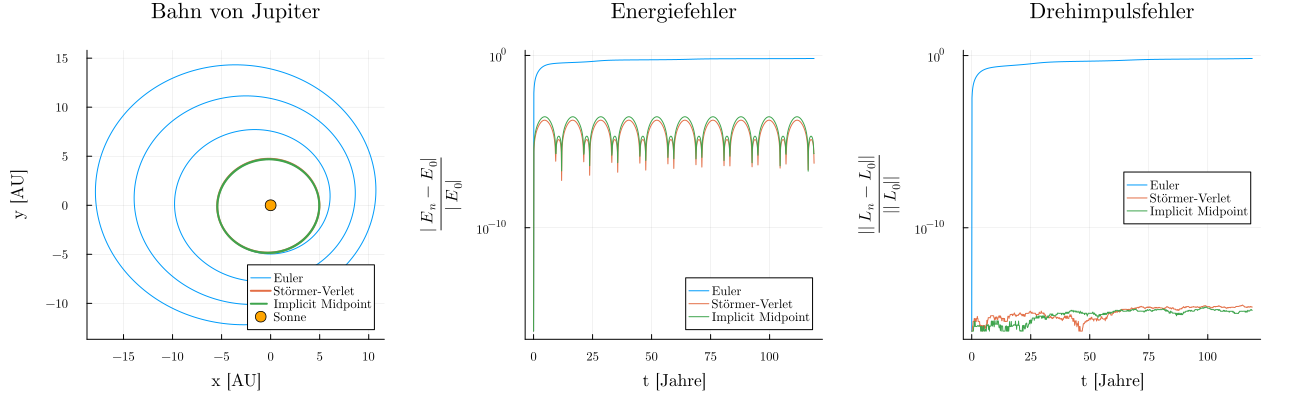

In [12]:
p1 = plot(xs(q_euler), ys(q_euler), label = "Euler", aspect_ratio = :equal,
          xlabel = "x [AU]", ylabel = "y [AU]", title = "Bahn von Jupiter", fontfamily = "Computer Modern")
plot!(p1, xs(q_verlet), ys(q_verlet), label = "Störmer-Verlet", linewidth = 2)
plot!(p1, xs(q_mid), ys(q_mid), label = "Implicit Midpoint", linestyle = :dash, linewidth = 2)
scatter!(p1, [0], [0], label = "Sonne", color = :orange, markersize = 6)

p2 = plot(t / 365.25, clip.(energy_error(q_euler, v_euler)), label = "Euler",
          yscale = :log10, xlabel = "t [Jahre]", ylabel = L"$\frac{|E_n - E_0|}{|E_0|}$",
          title = "Energiefehler", legend = :bottomright)
plot!(p2, t / 365.25, clip.(energy_error(q_verlet, v_verlet)), label = "Störmer-Verlet")
plot!(p2, t / 365.25, clip.(energy_error(q_mid, v_mid)), label = "Implicit Midpoint")

p3 = plot(t / 365.25, clip.(angmom_error(q_euler, v_euler)), label = "Euler",
          yscale = :log10, xlabel = "t [Jahre]", ylabel = L"$\frac{||L_n - L_0||}{||L_0||}$",
          title = "Drehimpulsfehler", legend = :right)
plot!(p3, t / 365.25, clip.(angmom_error(q_verlet, v_verlet)), label = "Störmer-Verlet")
plot!(p3, t / 365.25, clip.(angmom_error(q_mid, v_mid)), label = "Implicit Midpoint")

plot(p1, p2, p3, layout = (1, 3), size = (1300, 400), margin = 8Plots.mm)

In [13]:
n_list = [100, 200, 400, 800, 1600, 3200]
n_ref = 51200

# Referenz: Verlet mit sehr vielen Schritten, genau ein Umlauf (t = T)
_, q_ref_t, _ = integrate(verlet_step, acc, q_jup, v_jup, T / n_ref, n_ref)
q_ref = q_ref_t[end]

function final_error(step, n)
    _, q_t, _ = integrate(step, acc, q_jup, v_jup, T / n, n)
    return norm(q_t[end] - q_ref)
end

hs = [T / n for n in n_list]
err_euler  = [final_error(euler_step, n)    for n in n_list]
err_verlet = [final_error(verlet_step, n)   for n in n_list]
err_mid    = [final_error(midpoint_step, n) for n in n_list]

# Steigungen zwischen aufeinanderfolgenden Punkten (Halbierung von h)
slopes(err) = [log(err[i] / err[i+1]) / log(2) for i in 1:length(err)-1]
println("Euler:  ", round.(slopes(err_euler), digits = 2))
println("Verlet: ", round.(slopes(err_verlet), digits = 2))
println("Midpoint: ", round.(slopes(err_mid), digits = 2))

Euler:  [0.66, 0.79, 0.89, 0.94, 0.97]
Verlet: [2.0, 2.0, 2.0, 2.0, 2.0]
Midpoint: [2.01, 2.0, 2.0, 2.0, 2.0]


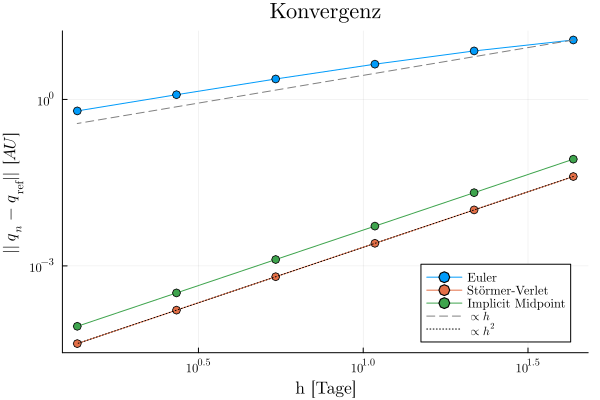

In [14]:
a1 = err_euler[1] / hs[1]       # Konstante für die Linie ∝ h
a2 = err_verlet[1] / hs[1]^2    # Konstante für die Linie ∝ h²

plot(hs, err_euler, label = "Euler", marker = :o, xscale = :log10, yscale = :log10,
     xlabel = "h [Tage]", ylabel = L"||q_n - q_\mathrm{ref}||\ [AU]", title = "Konvergenz",
     legend = :bottomright, fontfamily = "Computer Modern")
plot!(hs, err_verlet, label = "Störmer-Verlet", marker = :o)
plot!(hs, err_mid, label = "Implicit Midpoint", marker = :o)
plot!(hs, a1 .* hs, label = L"\propto h", linestyle = :dash, color = :gray)
plot!(hs, a2 .* hs .^ 2, label = L"\propto h^2", linestyle = :dot, color = :black)

## Teil 3: Das äußere Sonnensystem

Jetzt betrachten wir die Sonne, Jupiter, Saturn, Uranus, Neptun und Pluto (die inneren Planeten sind in der Masse der Sonne enthalten) – und die Sonne darf sich auch bewegen. Der Zustand ist jetzt eine $3 \times N$-Matrix $q$ (und $v$), wobei jede *Spalte* ein Körper ist. Die Anfangsdaten stammen aus dem Buch *Geometric Numerical Integration* von Hairer, Lubich und Wanner (Kap. I.2.4) und sind unten gegeben.

Die Beschleunigung von Körper $i$ ist
$$
a_i = \sum_{j \neq i} G\, m_j\, \frac{q_j - q_i}{\|q_j - q_i\|^3},
$$
die Gesamtenergie und der Gesamtdrehimpuls sind
$$
E = \sum_i \frac{1}{2} m_i \|v_i\|^2 - \sum_{i<j} \frac{G\, m_i m_j}{\|q_i - q_j\|}, \qquad L = \sum_i m_i\, q_i \times v_i .
$$

### Voraussetzungen

In [15]:
function outer_solar_system() # Namen, Massen m (Länge N), Positionen q (3 x N), Geschwindigkeiten v (3 x N)
    names = ["Sun", "Jupiter", "Saturn", "Uranus", "Neptune", "Pluto"]
    m = [1.00000597682, 0.000954786104043, 0.000285583733151,
         0.0000437273164546, 0.0000517759138449, 1 / 1.3e8]
    q = [0.0 -3.5023653 9.0755314 8.3101420 11.4707666 -15.5387357 ;
         0.0 -3.8169847 -3.0458353 -16.2901086 -25.7294829 -25.2225594 ;
         0.0 -1.5507963 -1.6483708 -7.2521278 -10.8169456 -3.1902382]
    v = [0.0 0.00565429 0.00168318 0.00354178 0.00288930 0.00276725 ;
         0.0 -0.00412490 0.00483525 0.00137102 0.00114527 -0.00170702 ;
         0.0 -0.00190589 0.00192462 0.00055029 0.00039677 -0.00136504]
    return names, m, q, v
end

outer_solar_system (generic function with 1 method)

### Anfangsdaten
- Anfangpositionen
- Geschwindigkeiten (linear ohne Einfluss)

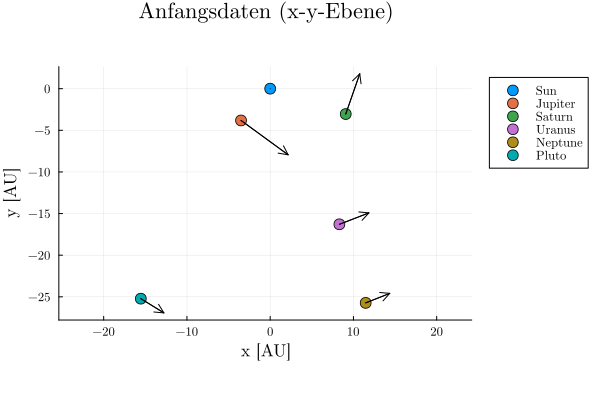

In [16]:
names, m, q, v = outer_solar_system()

p = plot(; aspect_ratio = :equal, xlabel = "x [AU]", ylabel = "y [AU]", title = "Anfangsdaten (x-y-Ebene)", legend = :outertopright, fontfamily = "Computer Modern")

for i in eachindex(names)
    scatter!(p, [q[1, i]], [q[2, i]]; label = names[i], markersize = 6)
end

# Geschwindigkeiten als Pfeile (skaliert, sonst unsichtbar klein)
s = 1000   # Pfeil = Strecke, die in 1000 Tagen mit v = konst. zurückgelegt werden würde
quiver!(p, q[1, :], q[2, :]; quiver = (s * v[1, :], s * v[2, :]), color = :black)

p

Sonne ruht, aber der Systemschwerpunkt bewegt sich. 
Funktion soll generiert werden um Positionen & Geschwindigkeiten **in-place** zu transformieren (vor allem die Anfangsdaten): 
```julia
function to_barycentre!(q, v, m)
    ...
end
```
Die Funktion soll die Positionen und Geschwindigkeiten **in-place** transformieren:
$$
q_i \to q_i - Q \\
v_i \to v_i - V
$$
wobei $Q =  \frac{1}{M} \sum_{i} m_i q_i ,  V = \frac{1}{M} \sum_i m_i v_i$ und $M = \sum_i m_i$

Transformiere die Anfangsdaten in dieses Koordinatensystem.

In [17]:
function to_barycentre!(q, v, m)
    M = sum(m)
    Q = q * m/M
    V = v * m/M
    q .-= Q
    v .-= V
    return q, v
end

names, m, q0, v0 = outer_solar_system()
to_barycentre!(q0, v0, m);

Weiter werden Funktionen implementiert, um die Interaktion zwischen den Planeten zu berücksichtigen.
Dabei sind relevant, die Beschleunigung der Körper, dessen Energie und deren Drehmoment. 

Es wird getestet `acceleration_nbody`: Nach dem 3. Newtonschen Gesetz muss $\sum_i m_i a_i = 0$ gelten.

In [18]:
function acceleration_nbody(q, m)
    N = length(m)
    a = zeros(3, N)
    for i in 1:N, j in 1:N
        i == j && continue # Selbstwechselwirkung überspringen
        d = q[:, j] - q[:, i]
        a[:, i] += G * m[j] * d / norm(d)^3
    end
    return a
end

function energy_nbody(q, v, m)
    N = length(m)
    E = 0.0
    for i in 1:N
        E += 0.5 * m[i] * dot(v[:, i], v[:, i])
        for j in i+1:N
            E -= G * m[i] * m[j] / norm(q[:, i] - q[:, j])
        end
    end
    return E
end

function angular_momentum_nbody(q, v, m)
    L = zeros(3)
    for i in eachindex(m)
        L += m[i] * cross(q[:, i], v[:, i])
    end
    return L
end

norm(acceleration_nbody(q0, m) * m) # soll annähernd null sein, wegen 3. Newton Gesetz

1.3974511994897761e-24

Simulation des äußerenm Sonnensystems in $2000$ Schritten, wobei jeder Schritt $h = 100$ Tagen (Gesamt ca. 548 Jahre):
- **explizites Eulerverfahren**,
- **Strömer-Verlet**, 
jeweils als Funktion der Zeit. 

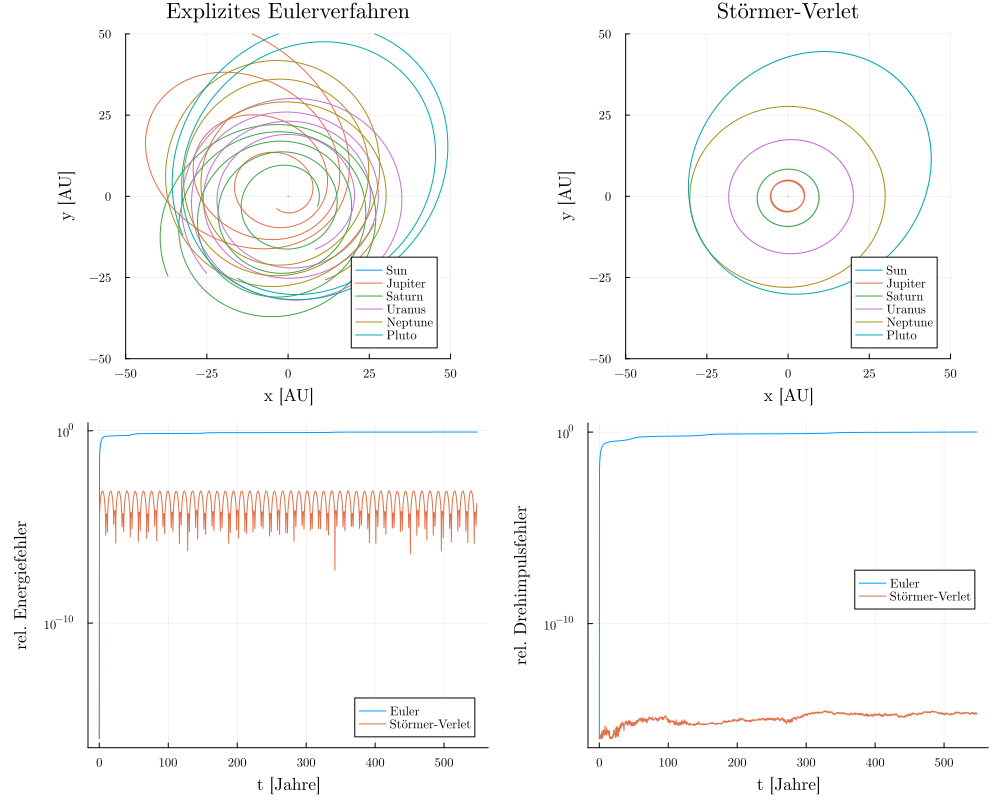

In [19]:
acc = q -> acceleration_nbody(q, m)
h = 100.0
N_steps = 2000

t_e, q_e, v_e = integrate(euler_step,  acc, q0, v0, h, N_steps)
t_v, q_v, v_v = integrate(verlet_step, acc, q0, v0, h, N_steps)

clip(x) = max(x, 1e-16)

function relative_errors(qs, vs, m)
    E = [energy_nbody(q, v, m) for (q, v) in zip(qs, vs)]
    L = [angular_momentum_nbody(q, v, m) for (q, v) in zip(qs, vs)]
    errE = abs.(E .- E[1]) ./ abs(E[1])
    errL = [norm(l - L[1]) / norm(L[1]) for l in L]
    return errE, errL
end

errE_e, errL_e = relative_errors(q_e, v_e, m)
errE_v, errL_v = relative_errors(q_v, v_v, m)

function plot_orbits(qs, names; title = "")
    p = plot(; xlims = (-50, 50), ylims = (-50, 50), aspect_ratio = :equal, xlabel = "x [AU]", ylabel = "y [AU]", title = title, legend = :bottomright)
    for i in eachindex(names)
        plot!(p, [q[1, i] for q in qs], [q[2, i] for q in qs]; label = names[i])
    end
    return p
end

p1 = plot_orbits(q_e, names; title = "Explizites Eulerverfahren")
p2 = plot_orbits(q_v, names; title = "Störmer-Verlet")

p3 = plot(t_e ./ 365.25, clip.(errE_e), yscale = :log10, label = "Euler", xlabel = "t [Jahre]", ylabel = "rel. Energiefehler", legend = :bottomright)
plot!(p3, t_v ./ 365.25, clip.(errE_v), label = "Störmer-Verlet")

p4 = plot(t_e ./ 365.25, clip.(errL_e), yscale = :log10, label = "Euler", xlabel = "t [Jahre]", ylabel = "rel. Drehimpulsfehler", legend = :right)
plot!(p4, t_v ./ 365.25, clip.(errL_v), label = "Störmer-Verlet")

plot(p1, p2, p3, p4, layout = (2, 2), size = (1000, 800), left_margin = 5Plots.mm, fontfamily = "Computer Modern")

**Ergebnis**
* **Euler:** Energie & Drehimpuls driften nahezu sofort ab (rel. Fehler $\approx 1$), die Planeten verlassen die festen Bahnen als Spiralen.
* **Störmer–Verlet:** Bahnen bleiben über $500+$ Jahre stabil. Der Energiefehler bleibt beschränkt und schwingt mit der Jupiterperiode ($\approx 12$ Jahre). Der Drehimpuls ist bis auf Rundungsfehler ($\approx 10^{-15}$) erhalten.
* **Grund:** Strömer-Verlet ist symplektisch (Phasenraumvolumen der Simulation, gleich dem der Planetendynamik), Euler nicht. Bei gleichem Aufwand pro Schritt ist Verlet für Langzeitsimulationen klar besser.

### Animation: Euler vs. Störmer–Verlet

┌ Info: Saved animation to c:\Users\mikar\Documents\math-programs\sonnensystem.gif
└ @ Plots C:\Users\mikar\.julia\packages\Plots\8ZnR3\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\mikar\\Documents\\math-programs\\sonnensystem.gif")
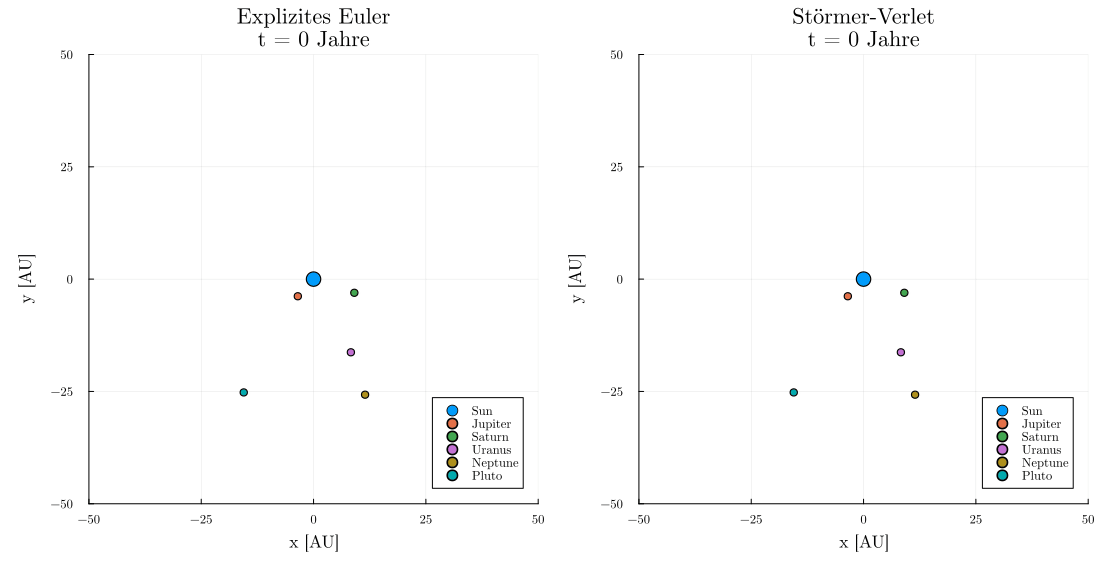

In [20]:
gr() # Backend

# ein Bild der Animation: aktuelle Positionen + bisherige Spur
function frame_plot(qs, t, n, names; title = "")
    p = plot(; xlims = (-50, 50), ylims = (-50, 50), aspect_ratio = :equal, xlabel = "x [AU]", ylabel = "y [AU]", legend = :bottomright, title = "$title\nt = $(round(Int, t[n] / 365.25)) Jahre")
    for i in eachindex(names)
        plot!(p, [q[1, i] for q in qs[1:n]], [q[2, i] for q in qs[1:n]]; color = i, label = "") # Spur
        scatter!(p, [qs[n][1, i]], [qs[n][2, i]]; color = i, markersize = i == 1 ? 8 : 4, label = names[i]) # Körper
    end
    return p
end

step_every = 10 # sonst 2001 Bilder

anim = @animate for n in 1:step_every:length(q_v)
    pe = frame_plot(q_e, t_e, n, names; title = "Explizites Euler")
    pv = frame_plot(q_v, t_v, n, names; title = "Störmer-Verlet")
    plot(pe, pv, layout = (1, 2), size = (1100, 580), left_margin = 8Plots.mm, bottom_margin = 8Plots.mm, top_margin = 3Plots.mm, fontfamily = "Computer Modern")
end

gif(anim, "sonnensystem.gif", fps = 20)